# Buổi C7: Phân loại nhiều nhóm, nhận dạng chữ số viết tay

**Hiện trường.** Bưu điện cần máy đọc **mã bưu chính viết tay** trên phong bì để chia thư tự động. Mỗi chữ số là một ảnh nhỏ, và đáp án là một trong **mười** nhóm (0 đến 9), không còn là có/không như C1 đến C6. Chị Hạnh, chị Mai... đều đã quen bài toán hai nhóm; buổi này hỏi: *"khi có mười nhóm thì mọi thứ đã học thay đổi ra sao?"*

**Câu hỏi của buổi này:** *mô hình hai nhóm mở rộng sang nhiều nhóm thế nào, và đọc kết quả mười nhóm bằng cách nào?*

**Mindset của người làm dữ liệu:** với nhiều nhóm, một con số độ đúng không còn đủ; ta cần **ma trận nhầm lẫn mười nhân mười** để biết *cặp nào hay bị nhầm*, vì đó mới là chỗ cải thiện được.

Dữ liệu `load_digits` là ảnh xám 8 × 8 điểm ảnh (64 cột), có sẵn trong sklearn. Buổi này dùng lại cú pháp từ A1 đến C6; chỉ giải thích điều **mới**.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 1 | Nhìn dữ liệu: mỗi ảnh là một dòng 64 số |
| Chặng 2 | Hồi quy logistic cho mười nhóm: softmax và mười bộ trọng số |
| Chặng 3 | Một-đấu-tất-cả và từng-cặp: hai cách chia bài toán |
| Chặng 4 | Ma trận nhầm lẫn 10 × 10 và ba kiểu trung bình F1 |
| Chặng 5 | Xem tận mắt những ca bị nhầm |
| Chặng 6 | So các mô hình và phán quyết |

## Chặng 1: Nhìn dữ liệu, mỗi ảnh là một dòng 64 số

**Câu hỏi:** máy "nhìn" một chữ số bằng cách nào?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

X shape: (1797, 64) | y classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
images per class: [178, 182, 177, 183, 181, 182, 181, 179, 174, 180]
pixel value range: 0.0 to 16.0


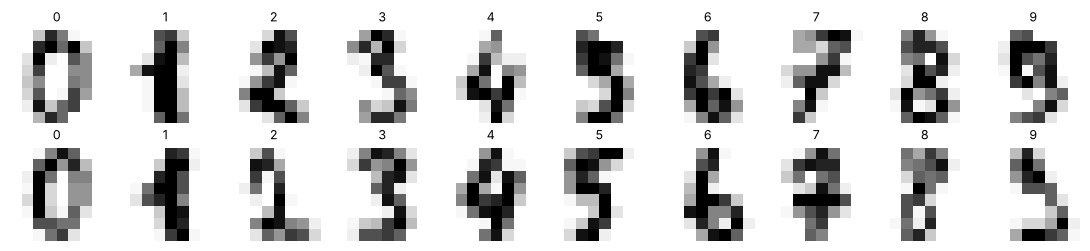

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
digits = load_digits(as_frame=True)
X, y = digits.data, digits.target
print("X shape:", X.shape, "| y classes:", y.unique().tolist())
print("images per class:", y.value_counts().sort_index().tolist())
print("pixel value range:", X.values.min(), "to", X.values.max())
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
fig, axes = plt.subplots(2, 10, figsize=(11, 2.6))
for ax, i in zip(axes.ravel(), range(20)):
    ax.imshow(digits.images[i], cmap="Greys"); ax.set_title(int(y.iloc[i]), fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `X, y = digits.data, digits.target`: `X` là bảng 1797 dòng × 64 cột: mỗi cột là **độ đậm của một điểm ảnh** (ảnh 8 × 8 được duỗi thành một hàng). `y` là chữ số thật.
- `y.value_counts().sort_index().tolist()`: đếm số ảnh mỗi nhóm theo thứ tự 0 đến 9: các nhóm **cân bằng** (khoảng 180 ảnh mỗi nhóm) nên độ đúng là thước đo tạm ổn.
- `X.values.min(), X.values.max()`: độ đậm từ 0 (trắng) đến 16 (đen), các cột cùng thang nên không cần chuẩn hóa.
- `stratify=y`: (đã học) giữ tỉ lệ mười nhóm như nhau ở tập học và tập thi.
- `digits.images[i]`: ảnh gốc dạng lưới 8 × 8 để vẽ; `imshow(..., cmap="Greys")` tô điểm ảnh đậm nhạt.
- `ax.axis("off")`: tắt trục tọa độ cho ảnh gọn.

**Cách đọc:** mỗi chữ số chỉ là lưới **8 × 8** rất thô; có ảnh người cũng phải nheo mắt mới đọc ra. Đây là lý do bài toán không hề tầm thường dù chỉ có mười nhóm.

**Mang về chặng 1:** ảnh nhỏ biến thành bảng bằng cách **duỗi mỗi điểm ảnh thành một cột**; mười nhóm cân bằng.

## Chặng 2: Hồi quy logistic cho mười nhóm, softmax và mười bộ trọng số

**Câu hỏi:** logistic ở C1 chỉ có một đường biên cho hai nhóm. Mười nhóm thì sao?

`LogisticRegression` tự xử lý: nó học **mười bộ trọng số** (mỗi nhóm một bộ, mỗi bộ 64 số), tính điểm cho từng nhóm rồi dùng hàm **softmax** để đổi mười điểm thành mười xác suất **cộng lại bằng 1** (softmax là phiên bản nhiều nhóm của sigmoid).

coef_ shape: (10, 64) | intercept_ shape: (10,)
classes_: [0 1 2 3 4 5 6 7 8 9]
accuracy: train 1.0 | test 0.962
first test image, 10 probabilities: [0.    0.095 0.    0.    0.    0.036 0.029 0.    0.839 0.   ] | sum = 1.0


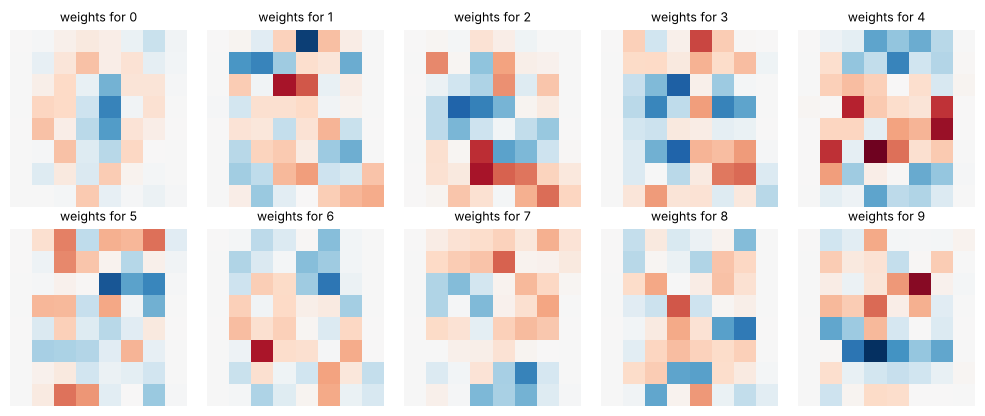

In [3]:
from sklearn.linear_model import LogisticRegression
softmax_model = LogisticRegression(max_iter=2000).fit(X_train, y_train)
print("coef_ shape:", softmax_model.coef_.shape, "| intercept_ shape:", softmax_model.intercept_.shape)
print("classes_:", softmax_model.classes_)
print("accuracy: train", round(softmax_model.score(X_train, y_train), 3), "| test", round(softmax_model.score(X_test, y_test), 3))
probs = softmax_model.predict_proba(X_test)
print("first test image, 10 probabilities:", probs[0].round(3), "| sum =", probs[0].sum().round(3))
fig, axes = plt.subplots(2, 5, figsize=(10, 4.2))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(softmax_model.coef_[k].reshape(8, 8), cmap="RdBu_r", vmin=-0.6, vmax=0.6); ax.set_title(f"weights for {k}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `LogisticRegression(max_iter=2000)`: (đã học) cho phép tối đa 2000 vòng lặp để máy kịp hội tụ. Với nhiều nhóm, sklearn mặc định dùng softmax.
- `softmax_model.coef_.shape`: **mới:** `coef_` giờ là bảng **10 × 64**: mười hàng (mỗi nhóm một bộ trọng số) × 64 cột (mỗi điểm ảnh một trọng số).
- `softmax_model.classes_`: thứ tự nhóm của các hàng và các cột `predict_proba`.
- `softmax_model.predict_proba(X_test)`: mỗi ảnh nhận **mười xác suất**, cộng bằng 1; nhãn dự đoán là nhóm xác suất cao nhất.
- `softmax_model.coef_[k].reshape(8, 8)`: gập 64 trọng số của nhóm `k` về lưới 8 × 8 để **vẽ như một bức ảnh**: ô đỏ là điểm ảnh *đậm thì nghiêng về nhóm k*, ô xanh là *đậm thì nghiêng ra khỏi nhóm k*.

**Cách đọc**

- **Con số:** `coef_` là 10 × 64. Độ đúng train **1,000**, test **0,962**: mô hình thuộc lòng tập học nhưng vẫn đọc đúng khoảng 96 trên 100 ảnh mới.
- **Bức tranh:** tám bức ảnh trọng số trông **lốm đốm đỏ xanh, không giống nét chữ số** như ta mong. Lý do: 64 điểm ảnh liền kề tương quan mạnh nên máy có vô số cách chia trọng số cho cùng một kết quả, và với `C` mặc định nó dùng cách *ôm sát tập học* (train đúng 100%). Hình trọng số chỉ cho biết điểm ảnh nào *có dính dáng*, đừng kỳ vọng đọc được như tranh: đây là bài học thành thật về giới hạn của việc "đọc hệ số" khi các cột tương quan (nhớ B3).
- **Ý nghĩa:** khoảng cách giữa train và test (chút quá khớp) nhắc ta thử `C` nhỏ hơn nếu cần; nhưng 96% là điểm xuất phát tốt.

**Mang về chặng 2:** nhiều nhóm = `coef_` có **một hàng mỗi nhóm**; softmax cho xác suất cộng bằng 1; trọng số của ảnh vẽ ra được nhưng *không nhất thiết dễ hiểu*.

## Chặng 3: Một-đấu-tất-cả và từng-cặp, hai cách chia bài toán

**Câu hỏi:** mô hình chỉ biết hai nhóm (như SVM ở C6) thì xử lý mười nhóm thế nào?

Có hai cách chia nhỏ:

- **Một-đấu-tất-cả (OvR, one-vs-rest):** huấn luyện **10** mô hình hai nhóm, mỗi mô hình hỏi "chữ số này **có phải số k** không?". Chọn nhóm có điểm cao nhất.
- **Từng-cặp (OvO, one-vs-one):** huấn luyện **45** mô hình, mỗi mô hình chỉ phân biệt **một cặp** (3 với 8, 4 với 9...). Mười nhóm có 10 × 9 / 2 = 45 cặp. Mỗi mô hình bỏ một phiếu; nhóm nhiều phiếu nhất thắng.

In [4]:
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
ovr = OneVsRestClassifier(LogisticRegression(max_iter=2000)).fit(X_train, y_train)
ovo = OneVsOneClassifier(LogisticRegression(max_iter=2000)).fit(X_train, y_train)
for name, m in [("softmax (native)", softmax_model), ("one-vs-rest", ovr), ("one-vs-one", ovo)]:
    n_models = len(m.estimators_) if hasattr(m, "estimators_") else 1
    print(f"{name:<18} binary models: {n_models:>2} | test accuracy: {m.score(X_test, y_test):.3f}")

softmax (native)   binary models:  1 | test accuracy: 0.962
one-vs-rest        binary models: 10 | test accuracy: 0.958
one-vs-one         binary models: 45 | test accuracy: 0.982


**Giải thích từng dòng**

- `OneVsRestClassifier(LogisticRegression(...))`: **mới:** `OneVsRestClassifier` *bọc* một mô hình hai nhóm bất kỳ và biến nó thành mười mô hình một-đấu-tất-cả.
- `OneVsOneClassifier(...)`: **mới:** tương tự, nhưng tạo mô hình cho **từng cặp** nhóm.
- `len(m.estimators_) if hasattr(m, "estimators_") else 1`: `estimators_` là danh sách các mô hình con; `hasattr` kiểm tra mô hình có thuộc tính đó không. Softmax gốc chỉ là **một** mô hình.
- `f"{name:<18} ... {n_models:>2}"`: canh trái 18 ký tự, canh phải 2 ký tự cho bảng thẳng hàng.

**Cách đọc:** softmax 0,962, một-đấu-tất-cả 0,958 với 10 mô hình, từng-cặp **0,982** với 45 mô hình. Từng-cặp nhỉnh hơn vì mỗi mô hình con chỉ lo một việc dễ (phân biệt hai số), nhưng tốn nhiều mô hình hơn. Cách nào cũng dùng được: chênh vài phần trăm trên 450 ảnh thi tương đương *vài ảnh*, nên đừng kết luận quá tay.

Mô hình nào tự biết nhiều nhóm (cây, k-NN, Naive Bayes, softmax) thì không cần bọc. `SVC` bên trong **dùng từng-cặp** mà ta không thấy.

**Mang về chặng 3:** OvR = *k* mô hình, OvO = *k(k−1)/2* mô hình; hai cách bọc `OneVsRestClassifier`, `OneVsOneClassifier` dùng được với mọi mô hình hai nhóm.

## Chặng 4: Ma trận nhầm lẫn 10 × 10 và ba kiểu trung bình F1

**Câu hỏi:** độ đúng 96% không nói *số nào* hay bị đọc nhầm. Làm sao biết?

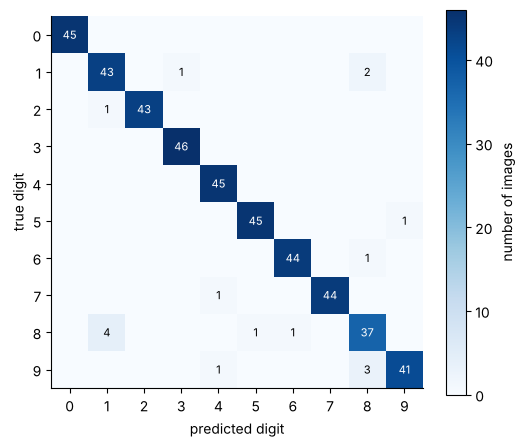

most frequent mistakes (count, true -> predicted): [(4, '8->1'), (3, '9->8'), (2, '1->8'), (1, '9->4'), (1, '8->6')]
F1 macro    : 0.9619
F1 micro    : 0.9622
F1 weighted : 0.9623
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        45
           1       0.90      0.93      0.91        46
           2       1.00      0.98      0.99        44
           3       0.98      1.00      0.99        46
           4       0.96      1.00      0.98        45
           5       0.98      0.98      0.98        46
           6       0.98      0.98      0.98        45
           7       1.00      0.98      0.99        45
           8       0.86      0.86      0.86        43
           9       0.98      0.91      0.94        45

    accuracy                           0.96       450
   macro avg       0.96      0.96      0.96       450
weighted avg       0.96      0.96      0.96       450



In [5]:
from sklearn.metrics import confusion_matrix, f1_score, classification_report
pred = softmax_model.predict(X_test)
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_xlabel("predicted digit"); ax.set_ylabel("true digit")
for i in range(10):
    for j in range(10):
        if cm[i, j] > 0:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im, label="number of images"); plt.show()
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(off[i, j], i, j) for i in range(10) for j in range(10) if off[i, j] > 0], reverse=True)[:5]
print("most frequent mistakes (count, true -> predicted):", [(int(c), f"{a}->{b}") for c, a, b in pairs])
for avg in ["macro", "micro", "weighted"]:
    print(f"F1 {avg:<9}: {f1_score(y_test, pred, average=avg):.4f}")
print(classification_report(y_test, pred, digits=2))

**Giải thích từng dòng**

- `confusion_matrix(y_test, pred)`: (đã học ở C2) giờ là bảng **10 × 10**: hàng là số thật, cột là số máy đoán; **đường chéo là đoán đúng**, ngoài đường chéo là nhầm.
- `np.fill_diagonal(off, 0)`: xóa đường chéo (đặt 0) để chỉ còn các ô *nhầm*.
- `sorted([...], reverse=True)[:5]`: xếp các ô nhầm từ nhiều đến ít, lấy năm ô đầu.
- `f1_score(y_test, pred, average=avg)`: **mới:** với nhiều nhóm, F1 cần một cách *gộp*: `macro` = **trung bình đều** F1 của từng nhóm (mọi nhóm nặng như nhau); `micro` = gộp mọi ca rồi tính một lần (kết quả trùng độ đúng); `weighted` = trung bình có trọng số theo số ca mỗi nhóm.
- `classification_report(y_test, pred, digits=2)`: bảng precision, recall, F1 **từng chữ số** cùng ba dòng trung bình ở cuối.

**Cách đọc**

- **Con số:** có **17** ảnh bị đọc nhầm trên 450. Cặp nhầm nhiều nhất: 8 bị đọc thành 1 (4 lần), 9 bị đọc thành 8 (3 lần), 1 bị đọc thành 8 (2 lần). F1 macro 0,962, micro 0,962, weighted 0,962.
- **Bức tranh:** đường chéo đậm rõ, ô ngoài đường chéo gần như trắng; nhầm lẫn rải rác ở vài cặp *hình dạng gần nhau*.
- **Ý nghĩa:** ba kiểu trung bình **gần bằng nhau** ở đây vì mười nhóm *cân bằng*. Chúng chỉ tách xa khi nhóm lệch số lượng (C8): khi đó `macro` cho thấy nhóm nhỏ bị bỏ rơi còn `micro` thì che đi. Quy tắc nghề: **báo cáo `macro` nếu mọi nhóm đều quan trọng ngang nhau**.

**Mang về chặng 4:** ma trận nhầm lẫn 10 × 10 chỉ ra *cặp* hay nhầm; F1 nhiều nhóm có ba kiểu gộp (`macro`, `micro`, `weighted`).

## Chặng 5: Xem tận mắt những ca bị nhầm

**Câu hỏi:** những ảnh bị nhầm trông thế nào, máy dở hay ảnh quá xấu?

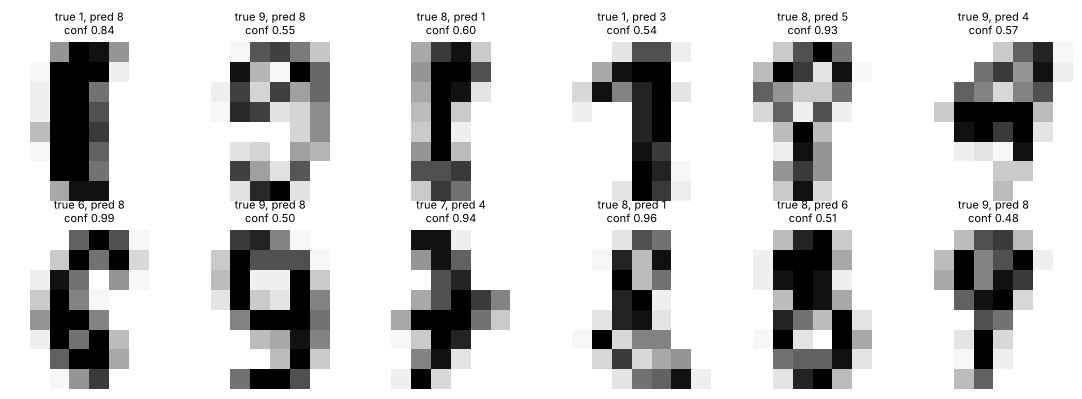

average confidence: right answers 0.986 | wrong answers 0.743


In [6]:
wrong = np.where(pred != y_test.values)[0]
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, k in zip(axes.ravel(), wrong[:12]):
    ax.imshow(X_test.iloc[k].values.reshape(8, 8), cmap="Greys")
    ax.set_title(f"true {y_test.iloc[k]}, pred {pred[k]}\nconf {probs[k].max():.2f}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()
print("average confidence: right answers", round(probs.max(axis=1)[pred == y_test.values].mean(), 3), "| wrong answers", round(probs.max(axis=1)[pred != y_test.values].mean(), 3))

**Giải thích từng dòng**

- `wrong = np.where(pred != y_test.values)[0]`: vị trí các ảnh đoán sai (`pred != ...` cho dãy đúng/sai, `np.where` lấy chỗ sai).
- `X_test.iloc[k].values.reshape(8, 8)`: đổi một dòng 64 số về lại ảnh 8 × 8 để vẽ.
- `probs[k].max()`: xác suất của nhóm máy chọn: **độ tự tin**.
- `probs.max(axis=1)[pred == y_test.values].mean()`: độ tự tin trung bình của các ca đúng, rồi các ca sai.

**Cách đọc:** nhiều ảnh sai là ảnh **mờ nét hoặc méo** (có ca người cũng phải do dự, có ca như số 1 đọc thành 8 thì khá lạ) (nét đứt, nét méo, số 9 trông như 8...). Độ tự tin trung bình khi đúng là **0,99**, khi sai chỉ **0,74**: trung bình máy kém chắc hơn ở các ca sai, **nhưng vẫn có ca sai mà tự tin tới 0,9 trở lên** (xem tiêu đề hình): độ tự tin chỉ là *tín hiệu*, không phải bảo đảm.

Hệ quả thực tế cho bưu điện: thay vì để máy đoán mọi ảnh, đặt **ngưỡng tự tin** (ví dụ dưới 0,7 thì chuyển cho người đọc). Một phần nhỏ ảnh nhờ người đọc là cái giá rẻ để đưa lỗi tổng thể xuống thấp: cùng ý tưởng ngưỡng ở C2, nay áp dụng cho mười nhóm.

**Mang về chặng 5:** hãy *nhìn* các ca sai; độ tự tin thấp là tín hiệu để chuyển cho người.

## Chặng 6: So các mô hình và phán quyết

**Câu hỏi:** mô hình nào đọc tốt nhất mười chữ số?

In [7]:
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
candidates = {
    "logistic (softmax)": LogisticRegression(max_iter=2000),
    "SVM rbf": SVC(),
    "k-NN k=3": KNeighborsClassifier(n_neighbors=3),
    "Naive Bayes (multinomial)": MultinomialNB(),
    "tree depth 8": DecisionTreeClassifier(max_depth=8, random_state=0),
}
results = {n: cross_val_score(m, X_train, y_train, cv=cv) for n, m in candidates.items()}
table = pd.DataFrame({n: {"CV mean": s.mean(), "CV std": s.std()} for n, s in results.items()}).T.sort_values("CV mean", ascending=False).round(3)
print(table.to_string())

                           CV mean  CV std
SVM rbf                      0.986   0.008
k-NN k=3                     0.986   0.004
logistic (softmax)           0.963   0.012
Naive Bayes (multinomial)    0.900   0.019
tree depth 8                 0.846   0.021


**Giải thích từng dòng**

- `MultinomialNB()`: Naive Bayes cho số đếm (C4); độ đậm điểm ảnh không âm nên dùng được.
- `cv = RepeatedStratifiedKFold(...)`: kiểm định chéo lặp (đã học): 15 điểm mỗi mô hình.
- `sort_values("CV mean", ascending=False)`: xếp từ cao xuống thấp.

**Cách đọc:** thứ tự từ trên xuống: SVM rbf (0,986), k-NN k=3 (0,986), logistic (softmax) (0,963), Naive Bayes (multinomial) (0,900), tree depth 8 (0,846). Hai mô hình dựa trên **khoảng cách** (SVM RBF và k-NN) đứng đầu vì chữ số cùng nhóm *trông giống nhau* điểm ảnh theo điểm ảnh; cây đứng cuối vì mỗi câu hỏi chỉ nhìn một điểm ảnh, không bắt được "hình".

## Phán quyết và bài học nghề

**Phán quyết cho bưu điện.** Dùng **SVM RBF** (hoặc k-NN) làm mô hình chính vì hơn logistic rõ ràng ở bài toán ảnh; giữ logistic làm mốc. Đặt ngưỡng tự tin để chuyển các ca mơ hồ cho người đọc.

**Bài học nghề.**

1. **Nhiều nhóm = đổi cách chia (softmax, OvR, OvO), không đổi bản chất.**
2. **`coef_` có một hàng mỗi nhóm**; với ảnh, trọng số vẽ ra được thành lưới 8 × 8 nhưng khó đọc vì các điểm ảnh tương quan.
3. **Ma trận nhầm lẫn 10 × 10** chỉ ra *cặp* nhầm nhau.
4. **F1 nhiều nhóm: `macro` (mọi nhóm ngang nhau), `micro` (= độ đúng), `weighted`.**
5. **Độ tự tin thấp là lý do chuyển cho người.**

**Một điều thành thật:** bộ chữ số 8 × 8 này *rất dễ* so với ảnh thật (ảnh màu, góc chụp, ánh sáng); trên ảnh thật người ta dùng mạng nơ-ron tích chập (phần G). Con số 96 đến 99% ở đây không nên mang đi hứa hẹn cho bài toán ảnh khác.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 1 | Ảnh nhỏ thành bảng bằng cách duỗi mỗi điểm ảnh thành một cột. |
| 2 | Logistic nhiều nhóm có `coef_` 10 × 64 và softmax cho mười xác suất cộng bằng 1. |
| 3 | OvR dùng k mô hình, OvO dùng k(k−1)/2; `SVC` bên trong dùng OvO. |
| 4 | Ma trận nhầm lẫn 10 × 10 chỉ ra cặp hay nhầm; F1 có ba kiểu gộp: macro, micro, weighted. |
| 5 | Xem các ca sai và dùng độ tự tin để chuyển cho người. |
| 6 | Với ảnh, mô hình dựa trên khoảng cách (SVM RBF, k-NN) hơn mô hình thẳng và cây. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Hàm đổi nhiều điểm số thành xác suất cộng bằng 1 | softmax | `LogisticRegression` (nhiều nhóm) |
| Mỗi nhóm một mô hình hỏi "có phải nhóm này không" | một-đấu-tất-cả (OvR) | `OneVsRestClassifier` |
| Mỗi cặp nhóm một mô hình | từng-cặp (OvO) | `OneVsOneClassifier` |
| Bảng nhầm lẫn mười nhân mười | ma trận nhầm lẫn | `confusion_matrix` |
| Trung bình đều F1 từng nhóm | macro F1 | `f1_score(average="macro")` |
| Gộp mọi ca rồi tính một lần | micro F1 | `f1_score(average="micro")` |
| Trung bình F1 có trọng số theo số ca | weighted F1 | `f1_score(average="weighted")` |
| Báo cáo từng nhóm | báo cáo phân loại | `classification_report` |
| Xác suất của nhóm được chọn | độ tự tin | `predict_proba(...).max(axis=1)` |

**Thử thách tự làm**

1. Chọn một cặp hay nhầm (ví dụ 3 và 8). Vẽ riêng các ảnh bị nhầm thành nhau; bạn có phân biệt được không?
2. Đặt ngưỡng tự tin 0,9 và đếm: bao nhiêu ảnh chuyển cho người, và độ đúng của phần máy tự đọc là bao nhiêu?
3. Thử `LogisticRegression(C=0.01)` và so khoảng cách train với test. Có bớt quá khớp không?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Giải thích softmax và vì sao `coef_` có 10 hàng.
- [ ] Phân biệt OvR và OvO, đếm số mô hình mỗi cách.
- [ ] Đọc ma trận nhầm lẫn nhiều nhóm và tìm cặp hay nhầm.
- [ ] Chọn đúng kiểu trung bình F1 cho tình huống.
- [ ] Dùng độ tự tin để quyết định ca nào cần người xem.

## Phần thưởng (Tip pro): `macro` hay `weighted`: chọn theo hậu quả của việc bỏ rơi nhóm nhỏ


`weighted` cho điểm cao khi mô hình giỏi ở các nhóm *đông*, `macro` kéo điểm xuống nếu *một nhóm nhỏ* bị bỏ rơi. Nếu lỗi ở nhóm hiếm có hậu quả nặng (bệnh hiếm, gian lận), dùng `macro` hoặc đọc riêng từng dòng trong `classification_report`. Ở C8 ta sẽ thấy khác biệt này bằng số.